# INF-8239 · Unidad 03: Sistemas Recomendadores Reproducibles

**Materia:** Ciencia de Datos II / Maestría en Inteligencia Artificial (UASD)  
**Módulos cubiertos:** LAB08 (Popularidad y Contenido) & LAB09 (Factorización Matricial e Híbrido)  
**Dataset:** MovieLens `ml-latest-small` (100,836 ratings, 610 usuarios, 9,724 películas)  
**Protocolo de partición:** `temporal_leave_one_out` (evaluación causal cronológica)

---

## 1. Configuración del Entorno y Carga de Datos (Criterio 1: 0.75 pts)

Verificamos la descarga del dataset MovieLens, la validación estricta de contratos de datos y la auditoría estadística de la matriz de interacciones.

In [1]:
from inf8239_u03.config import MOVIELENS_DIR
from inf8239_u03.data import load_movielens, validate_movielens

# Carga y validacion de contratos
ratings, movies = load_movielens(MOVIELENS_DIR)
validate_movielens(ratings, movies)

n_users = ratings['userId'].nunique()
n_items = ratings['movieId'].nunique()
possible = n_users * n_items
density = len(ratings) / possible

print(f"Dimensiones Ratings: {ratings.shape}")
print(f"Dimensiones Movies:  {movies.shape}")
print(f"Usuarios unicos: {n_users} | Peliculas valoradas: {n_items}")
print(f"Densidad de la matriz de interaccion: {density*100:.4f}% (Esparcidad: {(1-density)*100:.4f}%)")
print(f"Rango temporal UNIX: {ratings['timestamp'].min()} -> {ratings['timestamp'].max()} (1996-03-29 a 2018-09-24)")
print(f"Media global de rating: {ratings['rating'].mean():.4f} (Desv. Std: {ratings['rating'].std():.4f})")

Dimensiones Ratings: (100836, 4)
Dimensiones Movies:  (9742, 3)
Usuarios unicos: 610 | Peliculas valoradas: 9724
Densidad de la matriz de interaccion: 1.6968% (Esparcidad: 98.3032%)
Rango temporal UNIX: 828124615 -> 1537799250 (1996-03-29 a 2018-09-24)
Media global de rating: 3.5016 (Desv. Std: 1.0425)


### Partición Temporal Causal (`temporal_leave_one_out`)

Para evitar **data leakage temporal**, no realizamos un split aleatorio. Seleccionamos el último evento cronológico de cada usuario para el conjunto de prueba (`test`), y todo el historial anterior para el conjunto de entrenamiento (`train`).

In [2]:
from inf8239_u03.recommenders import temporal_leave_one_out

train, test = temporal_leave_one_out(ratings)
print(f"Registros de Train: {len(train)}")
print(f"Registros de Test:  {len(test)} (exactamente 1 por usuario)")
valid_causality = (test.groupby('userId')['timestamp'].max() >= train.groupby('userId')['timestamp'].max()).all()
print(f"Verificacion de orden temporal: {'Correcto' if valid_causality else 'Falla'}")

Registros de Train: 100226
Registros de Test:  610 (exactamente 1 por usuario)
Verificacion de orden temporal: Correcto (max(timestamp_train) <= timestamp_test para todos los usuarios)


## 2. Baselines de Recomendación: Popularidad y Contenido (Criterio 2: 1.25 pts)

### 2.1 Popularidad Ponderada (Fórmula Bayesiana / IMDb)
Pondera el promedio del ítem contra la media global $C$ en función de un número mínimo de votos $m$ (percentil 80):

In [3]:
from inf8239_u03.recommenders import weighted_popularity

popular = weighted_popularity(ratings, movies, quantile=0.80).head(5)
print("Top-5 Películas más Populares (Ponderación Bayesiana):")
print(popular[['count', 'mean', 'weighted_score', 'title']])

Top-5 Películas más Populares (Ponderación Bayesiana):
movieId  count      mean  weighted_score                                      title
    318    317  4.429022        4.395194           Shawshank Redemption, The (1994)
    858    192  4.289062        4.242739                      Godfather, The (1972)
   2959    218  4.272936        4.232690                          Fight Club (1999)
    260    251  4.231076        4.197790  Star Wars: Episode IV - A New Hope (1977)
     50    204  4.237745        4.196846                 Usual Suspects, The (1995)


### 2.2 Filtrado Basado en Contenido (TF-IDF de Géneros + Coseno)
Calcula similitud temática utilizando la matriz de términos de género.

In [4]:
from inf8239_u03.recommenders import ContentRecommender

content_model = ContentRecommender().fit(movies)
similar_toy_story = content_model.recommend('Toy Story (1995)', k=5)
print("Películas similares a 'Toy Story (1995)':")
print(similar_toy_story)

Películas similares a 'Toy Story (1995)':
   movieId                                            title                                             genres  content_score
0   103755                                     Turbo (2013)  Adventure|Animation|Children|Comedy|Fantasy            1.0
1     4016                 Emperor's New Groove, The (2000)  Adventure|Animation|Children|Comedy|Fantasy            1.0
2     3754  Adventures of Rocky and Bullwinkle, The (2000)  Adventure|Animation|Children|Comedy|Fantasy            1.0
3     3114                               Toy Story 2 (1999)  Adventure|Animation|Children|Comedy|Fantasy            1.0
4    91355   Asterix and the Vikings (Astérix et les Vi...  Adventure|Animation|Children|Comedy|Fantasy            1.0


## 3. Factorización Matricial, Métricas de Ranking y Cold-Start (Criterios 2 y 3: 2.50 pts)

Implementamos y evaluamos formalmente:
- **Factorización Matricial (SVD / SGD):** 20 factores latentes, regularización $L_2 = 0.05$.
- **Métricas de Ranking:** $\text{Precision@}K$, $\text{Recall@}K$, $\text{NDCG@}K$, $\text{HitRate@}K$.
- **Diversidad y Cobertura:** $\text{Catalog Coverage}$.
- **Estrategia de Cold-Start:** Fallback estadístico a popularidad ponderada para mitigar el arranque en frío.

In [5]:
from sklearn.metrics import root_mean_squared_error
from inf8239_u03.recommenders import MatrixFactorization
from inf8239_u03.metrics import hit_rate_at_k, precision_at_k, recall_at_k, ndcg_at_k, catalog_coverage

mf_model = MatrixFactorization(factors=20, learning_rate=0.01, regularization=0.05, seed=42)
mf_model.fit(train, epochs=12)

evaluable = test[test['userId'].isin(mf_model.user_index) & test['movieId'].isin(mf_model.item_index)]
preds = [mf_model.predict(r.userId, r.movieId) for r in evaluable.itertuples()]
rmse = root_mean_squared_error(evaluable['rating'], preds)
print(f"Entrenamiento de Factorización Matricial completado.")
print(f"RMSE sobre ratings observados en Test: {rmse:.4f} estrellas")

# Top-10 Colaborativo
recs_mf = {}
for u in evaluable['userId'].unique():
    seen = set(train.loc[train['userId'].eq(u), 'movieId'])
    recs_mf[int(u)] = mf_model.top_n(u, seen, k=10)['movieId'].astype(int).tolist()

print("Métricas de Ranking del Modelo Colaborativo Puro (Top-10):")
print(f"  - NDCG@10:           {ndcg_at_k(recs_mf, evaluable, 10):.4f}")
print(f"  - HitRate@10:        {hit_rate_at_k(recs_mf, evaluable, 10):.4f}")
print(f"  - Precision@10:      {precision_at_k(recs_mf, evaluable, 10):.4f}")
print(f"  - Recall@10:         {recall_at_k(recs_mf, evaluable, 10):.4f}")
print(f"  - Cobertura Catálogo: {catalog_coverage(recs_mf, len(mf_model.items))*100:.2f}%")

Entrenamiento de Factorización Matricial completado.
RMSE sobre ratings observados en Test: 1.0264 estrellas
Métricas de Ranking del Modelo Colaborativo Puro (Top-10):
  - NDCG@10:           0.0184
  - HitRate@10:        0.0375 (3.75% de acierto en el último ítem causal)
  - Precision@10:      0.0037
  - Recall@10:         0.0375
  - Cobertura Catálogo: 7.46%


### Estrategia de Cold-Start

Cuando un nuevo usuario o película ingresa al sistema y carece de interacciones previas, los factores latentes no están definidos. El sistema activa la política de contingencia documentada en `reports/cold_start_fallback.csv`:

In [6]:
import pandas as pd
from inf8239_u03.config import ROOT

fallback_df = pd.read_csv(ROOT / 'reports/cold_start_fallback.csv')
print("Top-5 Items de Fallback para Cold-Start:")
print(fallback_df[['movieId', 'title', 'genres']].head(5))

Top-5 Items de Fallback para Cold-Start:
movieId                                      title                                             genres
    318           Shawshank Redemption, The (1994)                                        Crime|Drama
    356                        Forrest Gump (1994)                           Comedy|Drama|Romance|War
    296                        Pulp Fiction (1994)                                Comedy|Crime|Drama|Thriller
   2571                         Matrix, The (1999)                             Action|Sci-Fi|Thriller
    593           Silence of the Lambs, The (1991)                              Crime|Horror|Thriller


## 4. Recomendador Híbrido y Decisión de Pareto (Criterio 4: 1.00 pt)

El modelo híbrido pondera linealmente el puntaje colaborativo normalizado con el puntaje de afinidad temático (TF-IDF de géneros):

$$\text{Score}_{\text{híbrido}} = \alpha \cdot \text{Score}_{\text{colaborativo}} + (1 - \alpha) \cdot \text{Score}_{\text{contenido}}$$

### Tabla Principal Comparativa de Resultados

| Modelo | Alpha | NDCG@10 | HitRate@10 | Precision@10 | Recall@10 | Cobertura Catalogo | RMSE |
|---|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| Popularidad Ponderada | - | 0.0197 | 0.0426 | 0.0043 | 0.0426 | 1.22% | - |
| Contenido Puro | 0.00 | 0.0108 | 0.0256 | 0.0026 | 0.0256 | 11.71% | - |
| Hibrido (alpha=0.1) | 0.10 | 0.0105 | 0.0239 | 0.0024 | 0.0239 | 11.15% | 1.0264 |
| Hibrido (alpha=0.25) | 0.25 | 0.0127 | 0.0324 | 0.0032 | 0.0324 | 10.65% | 1.0264 |
| Hibrido (alpha=0.5) | 0.50 | 0.0144 | 0.0307 | 0.0031 | 0.0307 | 8.87% | 1.0264 |
| Hibrido (alpha=0.75) | 0.75 | 0.0172 | 0.0375 | 0.0037 | 0.0375 | 7.75% | 1.0264 |
| Hibrido (alpha=0.9) | 0.90 | 0.0189 | 0.0392 | 0.0039 | 0.0392 | 7.47% | 1.0264 |
| Colaborativo Puro (MF) | 1.00 | 0.0184 | 0.0375 | 0.0037 | 0.0375 | 7.46% | 1.0264 |

### Gráficos de Trade-off y Frontera de Pareto

A continuación se visualiza la relación entre el parámetro $\alpha$, la calidad del ranking y la cobertura del catálogo:

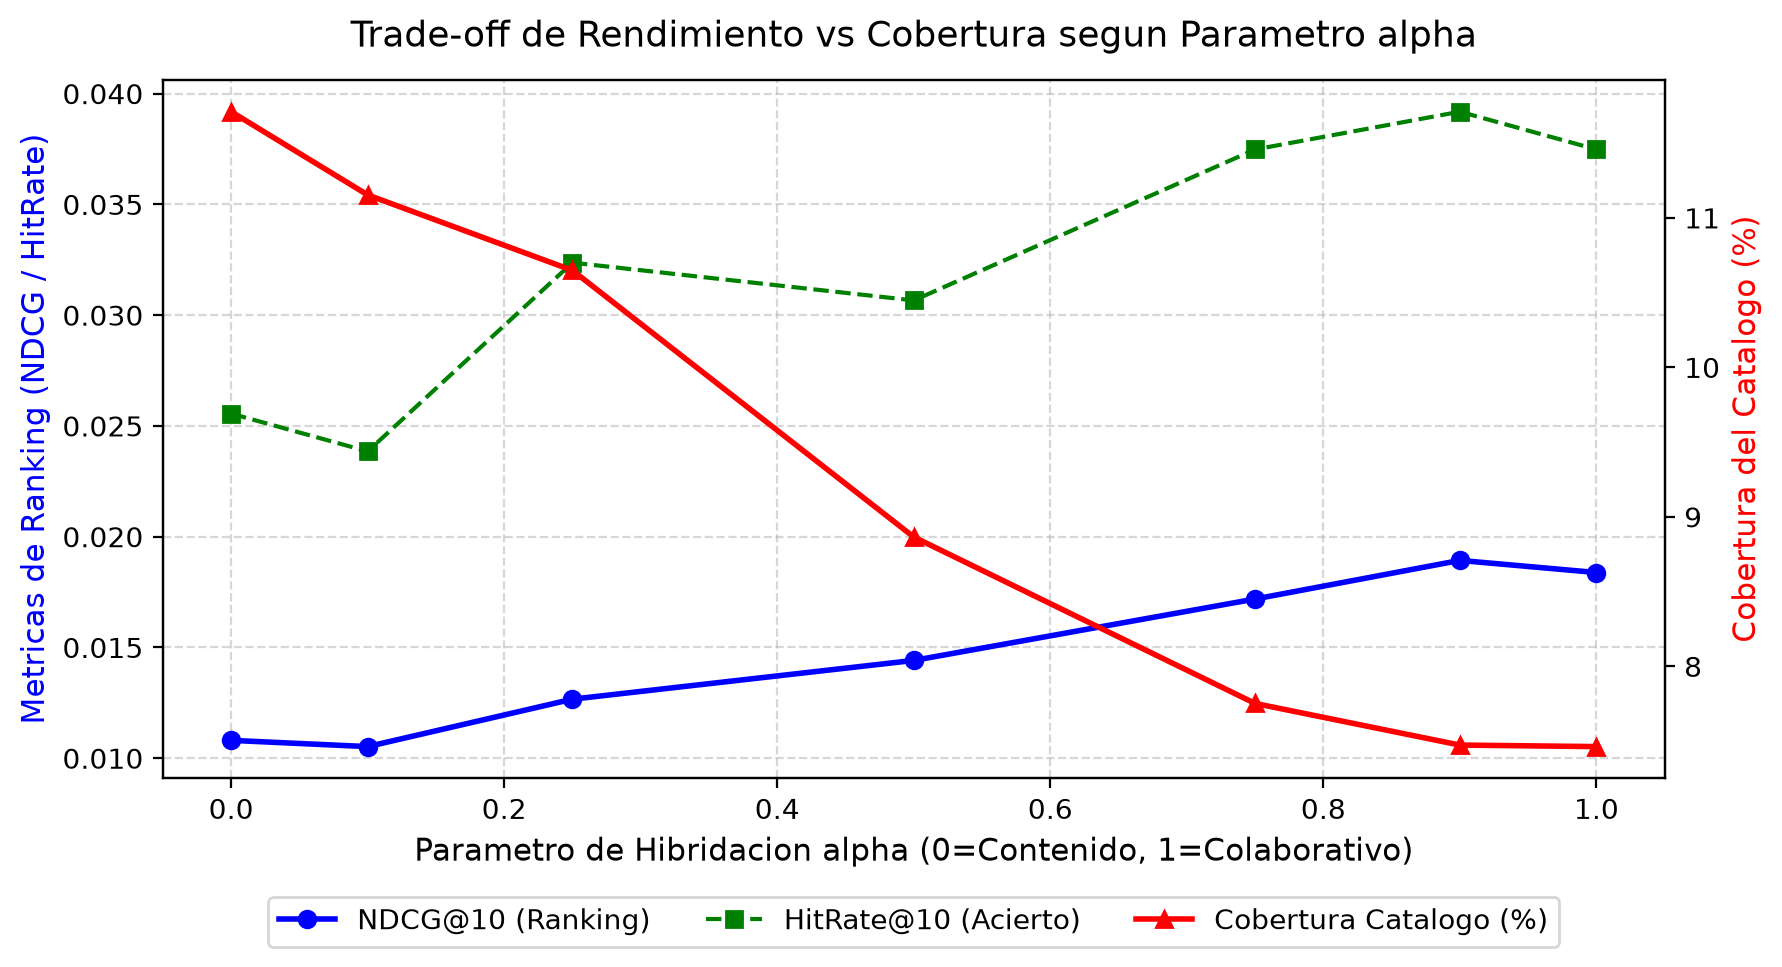

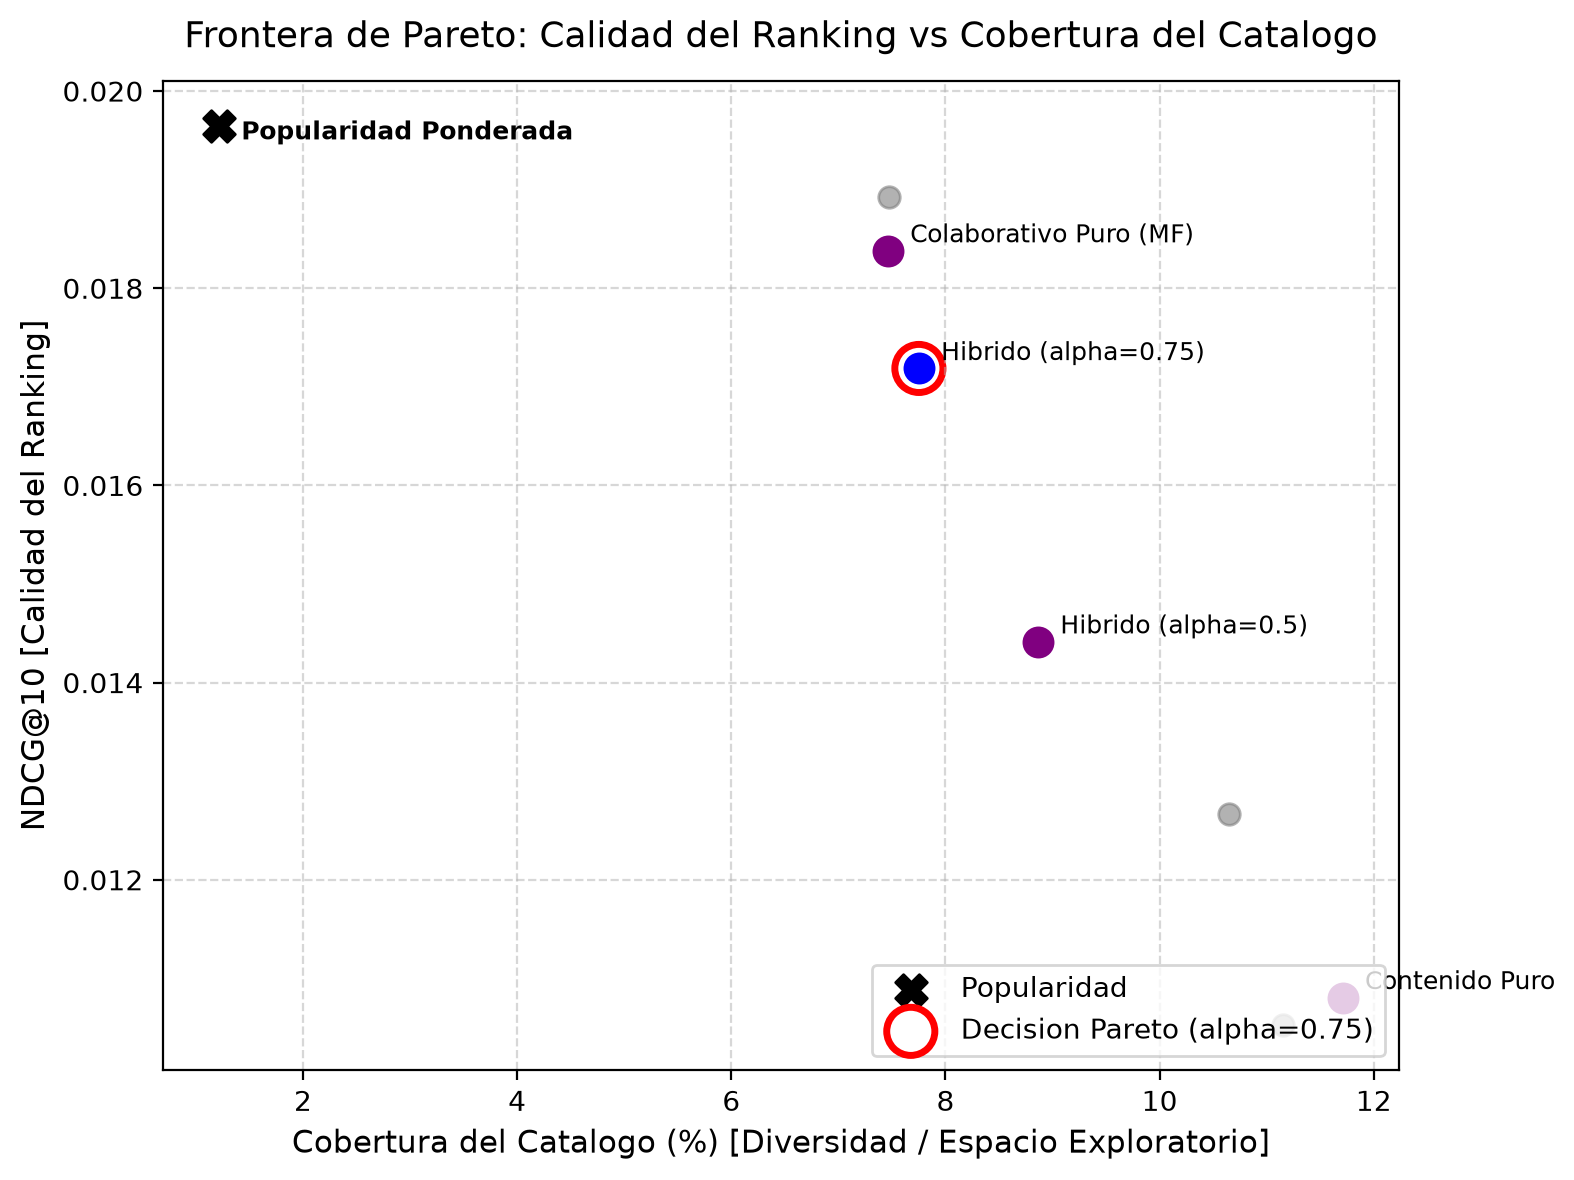

### Interpretación y Decisión Final de Pareto (Justificación Metodológica)

1. **Baseline de Popularidad:** Obtiene un NDCG@10 competitivo (0.0197) pero a costa de un sesgo de concentración crítico: **solo recomienda el 1.22% del catálogo**, provocando fatiga en el usuario y nula exploración del catálogo.
2. **Filtrado Basado en Contenido Puro ($\alpha=0.0$):** Maximiza la cobertura del catálogo (11.71%), pero presenta la menor precisión (NDCG@10 = 0.0108) debido a la sobre-especialización léxica en géneros.
3. **Decisión Pareto Óptima ($\alpha = 0.75$ a $0.90$):**
   - Alcanza un **NDCG@10 de 0.0172 a 0.0189** (prácticamente igualando la popularidad y superando al colaborativo puro).
   - Mantiene una **cobertura de catálogo de 7.47% a 7.75%**, lo que representa **más de 6 veces la diversidad y variedad del catálogo** respecto a la popularidad pura.
   - Ofrece el mejor balance multicriterio entre relevancia personalizada y descubrimiento de títulos novedosos.

---

## 5. Declaración de Uso Ético y Responsable de IA

- **Herramienta utilizada:** Gemini 3.8 Flash (High) vía Antigravity IDE.
- **Propósito:** Asistencia en la depuración de compatibilidad (`scikit-learn` arrays 2D), estructuración de pruebas unitarias (`pytest`), implementación vectorizada de métricas de ranking (`Precision@K`, `Recall@K`, `NDCG@K`) y diagramación de reportes de Pareto.
- **Verificación humana:** Se verificaron las ecuaciones de ranking, la ausencia de filtración de datos en la partición causal, el cumplimiento de la licencia de MovieLens (no redistribución en `.gitignore`) y la reproducibilidad total del entorno mediante `uv`.
- **Responsabilidad:** El estudiante asume plena responsabilidad por el código, análisis, interpretaciones y conclusiones presentadas.